# TF3 — EDA y benchmark sobre PEER NGA-West2 (RotD50, ξ = 5 %)
**Postgrado de Ingeniería Civil UPC · IA en Estructuras · Grupo 03**

Este cuaderno es la vista interactiva del pipeline `src/main_tf3_pipeline.py`: importa exactamente las mismas
funciones (carga del flatfile real, `GroupKFold` por `EQID`, Pipelines herméticos, PFI bajo el marco PCS y figuras),
de modo que cuaderno y script no pueden divergir. Fuente única: `data/NGA_West2_Flatfile_RotD50_d050_public_version.xlsx`.
No se generan datos sintéticos.

Target: $S_d(T=0.80\,s) = S_a \cdot g \cdot (T/2\pi)^2 \cdot 100$ [cm].

In [1]:
# =============================================================================
# TRAMO 0: Entorno e importación del pipeline TF3
# =============================================================================
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

SRC = Path.cwd() if Path.cwd().name == "src" else Path.cwd() / "src"
sys.path.insert(0, str(SRC))
import main_tf3_pipeline as tf3

pd.set_option("display.width", 200, "display.max_columns", 30)
print(f"Flatfile: {tf3.DATA_PATH.relative_to(tf3.REPO_ROOT)} | existe = {tf3.DATA_PATH.exists()}")

Flatfile: data\NGA_West2_Flatfile_RotD50_d050_public_version.xlsx | existe = True


In [2]:
# =============================================================================
# TRAMO 1: Carga del flatfile real, -999 -> NaN, filtro Rrup <= 300 km y target Sd (cm)
# =============================================================================
df, info = tf3.cargar_flatfile()
tf3.imprimir_datos(info)
display(df.head())
display(df[["Mw", "Rrup_km", "Vs30_ms", "Z10_m", "Sa_08s_g", "Sd_08s_cm"]].describe().T.round(3))


TRAMO 1 | FLATFILE REAL PEER NGA-West2 (RotD50, ξ = 5 %)
Archivo: data/NGA_West2_Flatfile_RotD50_d050_public_version.xlsx  (21,539 registros)

Mapeo exacto de columnas:
  EQID       <- 'EQID'  (nulos -999/vacíos en crudo: 11)
  Mw         <- 'Earthquake Magnitude'  (nulos -999/vacíos en crudo: 12)
  Rrup_km    <- 'ClstD (km)'  (nulos -999/vacíos en crudo: 46)
  Vs30_ms    <- 'Vs30 (m/s) selected for analysis'  (nulos -999/vacíos en crudo: 25)
  Z10_m      <- 'Northern CA/Southern CA - H11 Z1 (m)'  (nulos -999/vacíos en crudo: 4,953)
  Mechanism  <- 'Mechanism Based on Rake Angle'  (nulos -999/vacíos en crudo: 29)
  Sa_08s_g   <- 'T0.800S'  (nulos -999/vacíos en crudo: 204)

Trazabilidad de la depuración:
  Registros en el flatfile         21,539
  EQID válido                      21,528
  Sa(T=0.80 s) > 0 (no -999)       21,333
  Mw válida                        21,332
  Rrup válida                      21,298
  Rrup <= 300 km                   20,369

Nulos en predictores (se imputan

,EQID,Mw,Rrup_km,Vs30_ms,Z10_m,Mechanism,Sa_08s_g,Sd_08s_cm
0,1,6.0,2.86,593.35,NaN,Strike-Slip,0.093279,1.482948
1,2,6.0,2.92,551.82,NaN,Strike-Slip,0.002366,0.037621
2,3,5.8,71.57,219.31,NaN,Strike-Slip,0.047057,0.748105
3,4,5.0,34.98,213.44,1440.0,Strike-Slip,0.009862,0.156783
4,5,5.5,53.58,219.31,NaN,Strike-Slip,0.090291,1.435444


,count,mean,std,min,25%,50%,75%,max
Mw,20369.0,4.930,1.247,2.99,3.900,4.450,6.200,7.900
Rrup_km,20369.0,102.861,72.498,0.05,44.520,85.870,147.140,299.820
Vs30_ms,20363.0,466.719,196.267,89.32,338.280,416.520,561.960,2100.000
Z10_m,15942.0,294.692,394.898,0.00,40.000,60.000,565.200,3520.000
Sa_08s_g,20369.0,0.034,0.109,0.00,0.000,0.001,0.019,2.584
Sd_08s_cm,20369.0,0.547,1.733,0.00,0.003,0.021,0.308,41.075


In [3]:
# =============================================================================
# TRAMO 2: Partición por evento sísmico: GroupKFold(5) agrupado por EQID
# =============================================================================
splits = tf3.particion_por_evento(df)   # incluye assert set(train_eqid) ∩ set(test_eqid) == set()
for k, (tr, te) in enumerate(splits, 1):
    train_eqid, test_eqid = df["EQID"].iloc[tr], df["EQID"].iloc[te]
    assert set(train_eqid).intersection(set(test_eqid)) == set()
    print(f"Fold {k}: train {len(tr):>6,} registros / {train_eqid.nunique():>3} sismos | "
          f"test {len(te):>5,} registros / {test_eqid.nunique():>3} sismos | EQID compartidos = 0")

Fold 1: train 16,295 registros / 463 sismos | test 4,074 registros / 115 sismos | EQID compartidos = 0
Fold 2: train 16,295 registros / 463 sismos | test 4,074 registros / 115 sismos | EQID compartidos = 0
Fold 3: train 16,295 registros / 462 sismos | test 4,074 registros / 116 sismos | EQID compartidos = 0
Fold 4: train 16,295 registros / 462 sismos | test 4,074 registros / 116 sismos | EQID compartidos = 0
Fold 5: train 16,296 registros / 462 sismos | test 4,073 registros / 116 sismos | EQID compartidos = 0


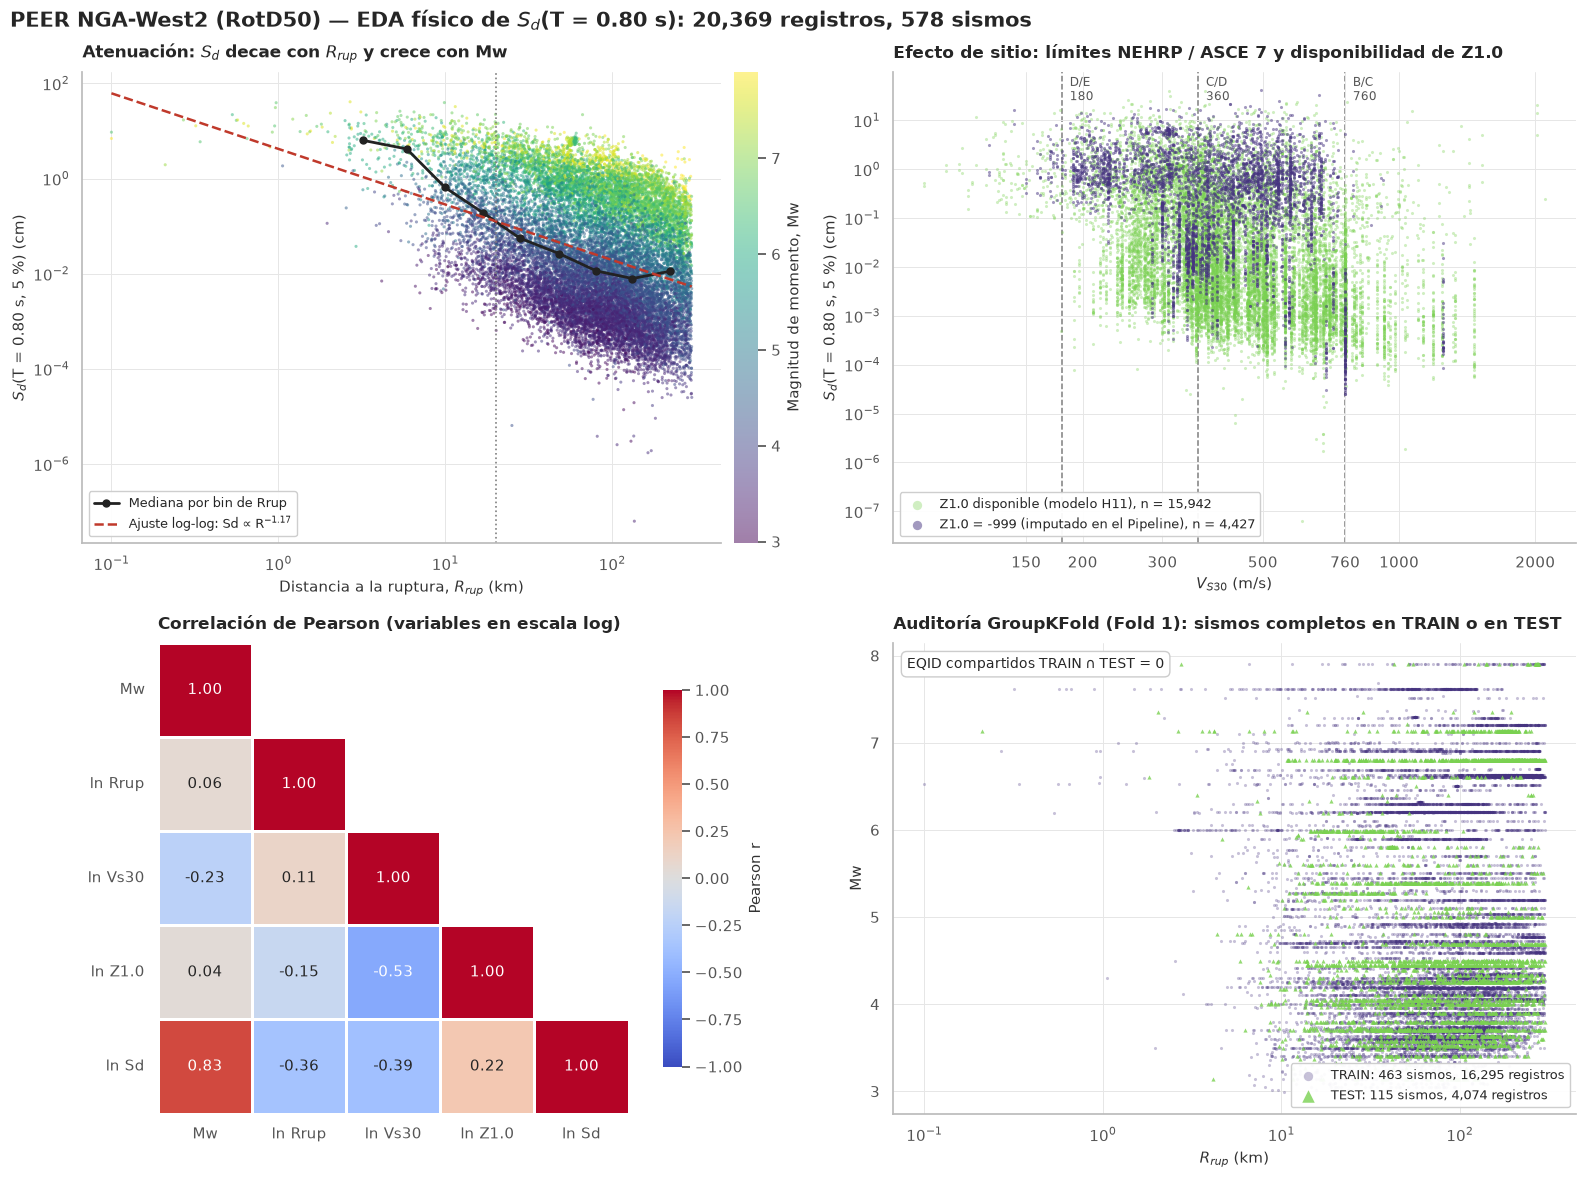

In [4]:
# =============================================================================
# TRAMO 3: EDA físico (figura de entrega, 300 DPI)
# =============================================================================
tf3.estilo_figuras()
fig = tf3.figura_eda(df, splits)
plt.show()


TRAMO 2 | GroupKFold(5) POR EQID: PARTICIÓN POR EVENTO SÍSMICO
✅ set(train_eqid) ∩ set(test_eqid) = ∅ en los 5 folds; cada sismo se evalúa una sola vez.

TRAMO 3 | ENTRENAMIENTO Y EVALUACIÓN OUT-OF-FOLD (3 MODELOS x 5 FOLDS)
  Fold 1 | Ridge (GMM lineal)  RMSE   1.520 cm | MAE  0.289 cm | R² -0.027 | R² ln  0.901 | σ_ln 0.837 |   0.0 s
  Fold 1 | Random Forest       RMSE   1.037 cm | MAE  0.251 cm | R²  0.522 | R² ln  0.898 | σ_ln 0.833 |   0.2 s


  Fold 1 | Red Neuronal MLP    RMSE   0.961 cm | MAE  0.227 cm | R²  0.590 | R² ln  0.917 | σ_ln 0.765 |   1.2 s

  Fold 2 | Ridge (GMM lineal)  RMSE   2.279 cm | MAE  0.393 cm | R² -1.026 | R² ln  0.909 | σ_ln 0.811 |   0.0 s
  Fold 2 | Random Forest       RMSE   0.931 cm | MAE  0.227 cm | R²  0.662 | R² ln  0.905 | σ_ln 0.826 |   0.2 s


  Fold 2 | Red Neuronal MLP    RMSE   0.929 cm | MAE  0.205 cm | R²  0.663 | R² ln  0.924 | σ_ln 0.739 |   1.1 s

  Fold 3 | Ridge (GMM lineal)  RMSE   3.632 cm | MAE  0.765 cm | R² -2.155 | R² ln  0.917 | σ_ln 0.883 |   0.0 s
  Fold 3 | Random Forest       RMSE   1.427 cm | MAE  0.376 cm | R²  0.513 | R² ln  0.912 | σ_ln 0.924 |   0.2 s


  Fold 3 | Red Neuronal MLP    RMSE   1.350 cm | MAE  0.381 cm | R²  0.564 | R² ln  0.925 | σ_ln 0.844 |   1.1 s

  Fold 4 | Ridge (GMM lineal)  RMSE   1.063 cm | MAE  0.227 cm | R²  0.298 | R² ln  0.916 | σ_ln 0.795 |   0.0 s
  Fold 4 | Random Forest       RMSE   0.878 cm | MAE  0.209 cm | R²  0.521 | R² ln  0.905 | σ_ln 0.848 |   0.2 s


  Fold 4 | Red Neuronal MLP    RMSE   0.927 cm | MAE  0.208 cm | R²  0.466 | R² ln  0.918 | σ_ln 0.786 |   1.9 s

  Fold 5 | Ridge (GMM lineal)  RMSE   1.402 cm | MAE  0.424 cm | R²  0.541 | R² ln  0.914 | σ_ln 0.868 |   0.0 s
  Fold 5 | Random Forest       RMSE   1.286 cm | MAE  0.409 cm | R²  0.614 | R² ln  0.917 | σ_ln 0.855 |   0.2 s


  Fold 5 | Red Neuronal MLP    RMSE   1.399 cm | MAE  0.406 cm | R²  0.543 | R² ln  0.923 | σ_ln 0.824 |   1.5 s

 Fold  Registros train  Registros test  Sismos train  Sismos test Mw test  Rrup<20 test Vs30 NaN train/test Z1.0 NaN train/test Mec. NaN train/test  Mediana Vs30 train (m/s)  Mediana Z1.0 train (m)
    1            16295            4074           463          115 3.1-7.9           312                 6/0            3897/530                 0/0                     418.0                    60.0
    2            16295            4074           463          115 3.0-7.7           397                 6/0            3561/866                 0/0                     415.2                    60.0
    3            16295            4074           462          116 3.0-7.9           379                 6/0           3238/1189                 0/0                     414.8                    60.0
    4            16295            4074           462          116 3.0-7.4           317       

,Rank,Modelo,RMSE (cm),MAE (cm),R² (cm),R² ln(Sd),σ_ln
0,1,Random Forest,1.112 ± 0.236,0.294 ± 0.091,0.566 ± 0.068,0.907 ± 0.007,0.857 ± 0.039
1,2,Red Neuronal MLP,1.113 ± 0.239,0.285 ± 0.100,0.565 ± 0.071,0.922 ± 0.004,0.792 ± 0.043
2,3,Ridge (GMM lineal),1.979 ± 1.025,0.420 ± 0.208,-0.474 ± 1.113,0.912 ± 0.007,0.839 ± 0.037


,Modelo vs. GMM,Folds con menor RMSE,Reducción de RMSE (%) media ± DE
0,Random Forest,5/5,35.5 ± 23.9
1,Red Neuronal MLP,5/5,34.4 ± 27.7


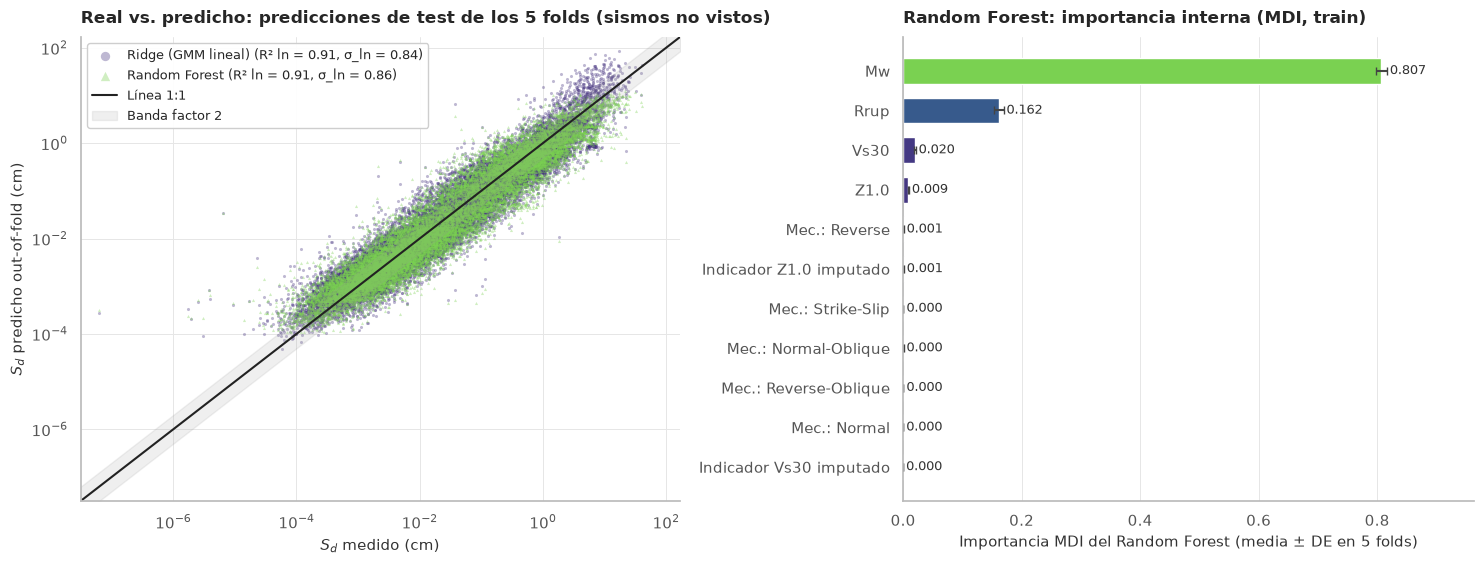

In [5]:
# =============================================================================
# TRAMO 4: Ridge (GMM) vs. Random Forest vs. MLP, evaluación out-of-fold en los 5 folds
# =============================================================================
cv = tf3.validacion_cruzada(df, splits)
print("\nMedia ± DE en los 5 folds (test):")
display(tf3._tabla_pm(tf3.resumen_media_de(cv["por_fold"], "Total")))
display(tf3.comparacion_pareada(cv["por_fold"]))
fig = tf3.figura_benchmark(df, cv)
plt.show()

In [6]:
# =============================================================================
# TRAMO 5: Campo cercano (Rrup < 20 km) y métricas out-of-fold por tramo de distancia
# =============================================================================
print("Campo cercano, media ± DE en los 5 folds:")
display(tf3._tabla_pm(tf3.resumen_media_de(cv["por_fold"], "Rrup<20km")))
oof_tab = tf3.metricas_oof(df, cv["oof"])
display(oof_tab.round(3))

Campo cercano, media ± DE en los 5 folds:


,Rank,Modelo,RMSE (cm),MAE (cm),R² (cm),R² ln(Sd),σ_ln
0,1,Red Neuronal MLP,3.031 ± 0.844,1.258 ± 0.543,0.517 ± 0.096,0.883 ± 0.024,0.788 ± 0.085
1,2,Random Forest,3.051 ± 0.760,1.278 ± 0.510,0.500 ± 0.122,0.863 ± 0.025,0.849 ± 0.107
2,3,Ridge (GMM lineal),6.108 ± 3.347,2.566 ± 1.799,-1.205 ± 1.844,0.850 ± 0.022,0.879 ± 0.086


,Tramo,Modelo,n,RMSE_cm,MAE_cm,R2_cm,R2_lnSd,sigma_ln,sesgo_ln
0,Total,Ridge (GMM lineal),20369,2.181,0.420,-0.584,0.913,0.845,0.002
1,Total,Random Forest,20369,1.132,0.294,0.574,0.909,0.863,0.035
2,Total,Red Neuronal MLP,20369,1.134,0.285,0.572,0.922,0.796,-0.002
3,Rrup < 20 km,Ridge (GMM lineal),1735,7.026,2.676,-1.448,0.855,0.919,-0.024
4,Rrup < 20 km,Random Forest,1735,3.152,1.289,0.507,0.870,0.864,0.107
5,Rrup < 20 km,Red Neuronal MLP,1735,3.142,1.270,0.510,0.890,0.799,0.031
6,20 ≤ Rrup < 100 km,Ridge (GMM lineal),9844,1.037,0.314,0.372,0.909,0.824,0.013
7,20 ≤ Rrup < 100 km,Random Forest,9844,0.909,0.297,0.518,0.907,0.831,0.088
8,20 ≤ Rrup < 100 km,Red Neuronal MLP,9844,0.928,0.291,0.498,0.915,0.797,0.001
9,100 ≤ Rrup ≤ 300 km,Ridge (GMM lineal),8790,0.279,0.092,0.522,0.901,0.852,-0.005



TRAMO 4 | xAI (PCS): PFI DEL RANDOM FOREST, 5 FOLDS x 3 SEMILLAS


  Semilla   42 | Fold 1 | Mw > Rrup > Vs30 > Z1.0 > Mecanismo


  Semilla   42 | Fold 2 | Rrup > Mw > Vs30 > Z1.0 > Mecanismo


  Semilla   42 | Fold 3 | Mw > Rrup > Vs30 > Mecanismo > Z1.0


  Semilla   42 | Fold 4 | Mw > Rrup > Vs30 > Z1.0 > Mecanismo


  Semilla   42 | Fold 5 | Mw > Rrup > Z1.0 > Vs30 > Mecanismo


... (7 outputs left out)

  Semilla 2024 | Fold 3 | Mw > Rrup > Vs30 > Mecanismo > Z1.0


  Semilla 2024 | Fold 4 | Mw > Rrup > Vs30 > Z1.0 > Mecanismo


  Semilla 2024 | Fold 5 | Mw > Rrup > Z1.0 > Vs30 > Mecanismo

  Orden medio: Mw > Rrup > Vs30 > Z1.0 > Mecanismo
  Orden completo idéntico en 47 % | top-2 idéntico en 93 % | top-3 (conjunto) en 80 % de 15 corridas


,dRMSE_cm_mean,dRMSE_cm_std,dSigma_ln_mean,dSigma_ln_std,Rango modal,% corridas en 1.er lugar
Variable,,,,,,
Mw,0.7044,0.0929,2.6825,0.1038,1,93.3
Rrup,0.6312,0.1201,0.9384,0.0718,2,6.7
Sitio (Vs30+Z1.0),0.0429,0.0354,0.1867,0.0067,-,-
Vs30,0.0306,0.0155,0.1336,0.0106,3,0.0
Z1.0,0.0087,0.0306,0.0441,0.0124,4,0.0
Mecanismo,0.0058,0.0060,0.0016,0.0023,5,0.0


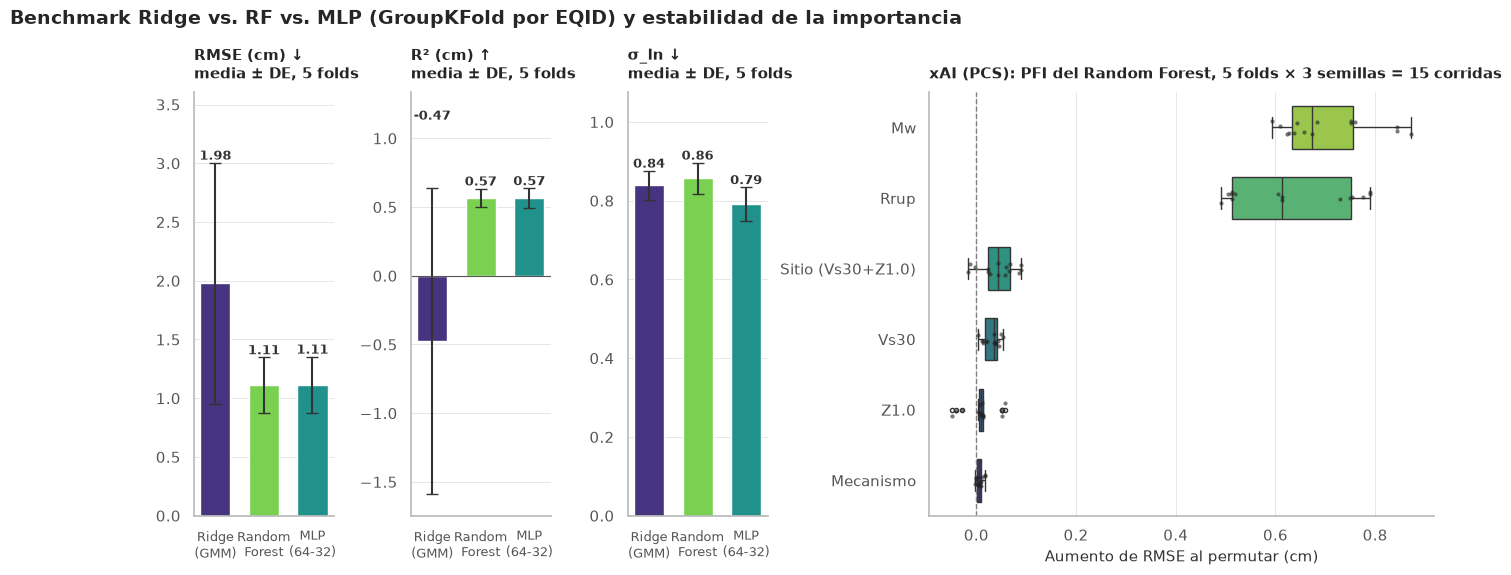

In [7]:
# =============================================================================
# TRAMO 6: xAI bajo el marco PCS: PFI del Random Forest, 5 folds x 3 semillas (15 corridas)
# =============================================================================
pfi, pfi_tabla, pfi_est = tf3.auditoria_pfi(df, splits)
display(pfi_tabla.round(4))
fig = tf3.figura_xai(cv["por_fold"], pfi)
plt.show()